# 実験1 (論文 第2〜4章): MoQ / AdaMoQ による非線形関数近似と Beale 関数解析

博士論文「慣性付準ニュートン法に基づくニューラルネットワークの学習アルゴリズムに関する研究」
(Shahrzad Mahboubi, 2023) 第2〜4章の再現実験を行う．

- **数値等価性検証**: PyTorch `MoQFamilyOptimizer` と GPU 並列バッチエンジンの一致確認 (倍精度 $\sim 10^{-14}$)
- **2.3節 Beale 関数**: 1次手法と2次手法 (`QN, NAQ, MoQ, AdaMoQ`) の最適化軌跡，および適応的慣性係数 $\mu_k$ の挙動
- **実験 1A (`f1(x, a)` 2次元関数近似)**: `2-55-1` ($d=221$, $|T_r|=3,320$, $|T_e|=6,600$, $R=10$ 試行)
- **実験 1B (5次元 Levy 関数近似)**: `5-50-1` ($d=351$, $|T_r|=5,000$, $|T_e|=2,500$, $R=10$ 試行)

In [1]:
import os
import sys
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())
os.environ.setdefault('MPLCONFIGDIR', os.path.join(os.getcwd(), '.mplconfig'))

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from model import FeedforwardMLP, half_mse_loss
from utils import (
    setup_japanese_matplotlib,
    adaptive_momentum_step_scalar,
    MoQFamilyOptimizer,
    beale_loss_and_grad,
    run_beale_trajectories,
    target_function_f1_2d,
    load_or_create_f1_2d_dataset,
    load_or_create_levy_5d_dataset,
    generate_initial_weights,
    run_first_order_batched,
    run_second_order_batched,
    format_moq_dataframe,
)

setup_japanese_matplotlib()
os.makedirs('../report/img', exist_ok=True)
os.makedirs('../datasets', exist_ok=True)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'PyTorch: {torch.__version__}, Device: {device}')
if device.type == 'cuda':
    print(f'GPU: {torch.cuda.get_device_name(0)}')

PyTorch: 2.7.1+cu118, Device: cuda
GPU: NVIDIA GeForce RTX 4080


## 1. `MoQFamilyOptimizer` と GPU 並列バッチエンジンの数値等価性検証 ($k=10$ ステップ)

In [2]:
torch.manual_seed(2023)
X_chk = torch.rand((64, 2), dtype=torch.float64, device=device) * 2.0 - 1.0
D_chk = torch.sin(X_chk[:, :1]) * X_chk[:, 1:2]
w_chk = generate_initial_weights(1, 2 * 10 + 10 + 10 * 1 + 1, seed=101, device=device)

eq_rows = []
for algo in ('QN', 'MSQN', 'NAQ', 'AdaNAQ', 'MoQ', 'AdaMoQ'):
    res_b = run_second_order_batched(
        algo=algo, w_init=w_chk, X_train=X_chk, XT_train=X_chk.t().contiguous(),
        D_train=D_chk, X_test=X_chk, D_test=D_chk, n_in=2, n_hid=10,
        max_epochs=10, show_pbar=False
    )
    net = FeedforwardMLP(2, 10, 1, dtype=torch.float64).to(device)
    net.set_flat_params(w_chk[0])
    opt = MoQFamilyOptimizer(net.parameters(), algo=algo)
    def closure(backward=True):
        opt.zero_grad()
        out = net(X_chk)
        loss = half_mse_loss(out, D_chk)
        if backward:
            loss.backward()
        return loss
    for _ in range(10):
        opt.step(closure)
    diff = float(torch.max(torch.abs(res_b['best_weights'] - net.get_flat_params())).item())
    eq_rows.append({'Algorithm': algo, 'Max |w_batched - w_optimizer| (k=10)': f'{diff:.3e}'})

pd.DataFrame(eq_rows)

,Algorithm,Max |w_batched - w_optimizer| (k=10)
0,QN,2.115e-14
1,MSQN,3.886e-15
2,NAQ,4.452e-14
3,AdaNAQ,2.565e-14
4,MoQ,1.515e-14
5,AdaMoQ,4.441e-14


## 2. Beale 関数 (式(24)) における最適化軌跡と適応的慣性係数 $\mu_k$ の特性

Algorithm  Iters     Final (x, y) Final f(x, y)
       GD   1000 (6.9802, 0.8356)     2.247e-01
       CM   1000 (5.3640, 0.7743)     1.561e-01
      NAG   1000 (5.6673, 0.7891)     1.717e-01
  AdaGrad   1000 (6.6863, 0.8271)     2.146e-01
  RMSprop   1000 (2.5232, 0.4725)     2.479e-01
 AdaDelta   1000 (6.3843, 0.8046)     2.521e-01
     Adam   1000 (3.2597, 0.5599)     8.345e-03
       QN     14 (3.0000, 0.5000)     1.701e-15
      NAQ     14 (3.0000, 0.5000)     9.299e-18
      MoQ     15 (3.0000, 0.5000)     1.290e-16
   AdaMoQ     16 (3.0000, 0.5000)     3.901e-19


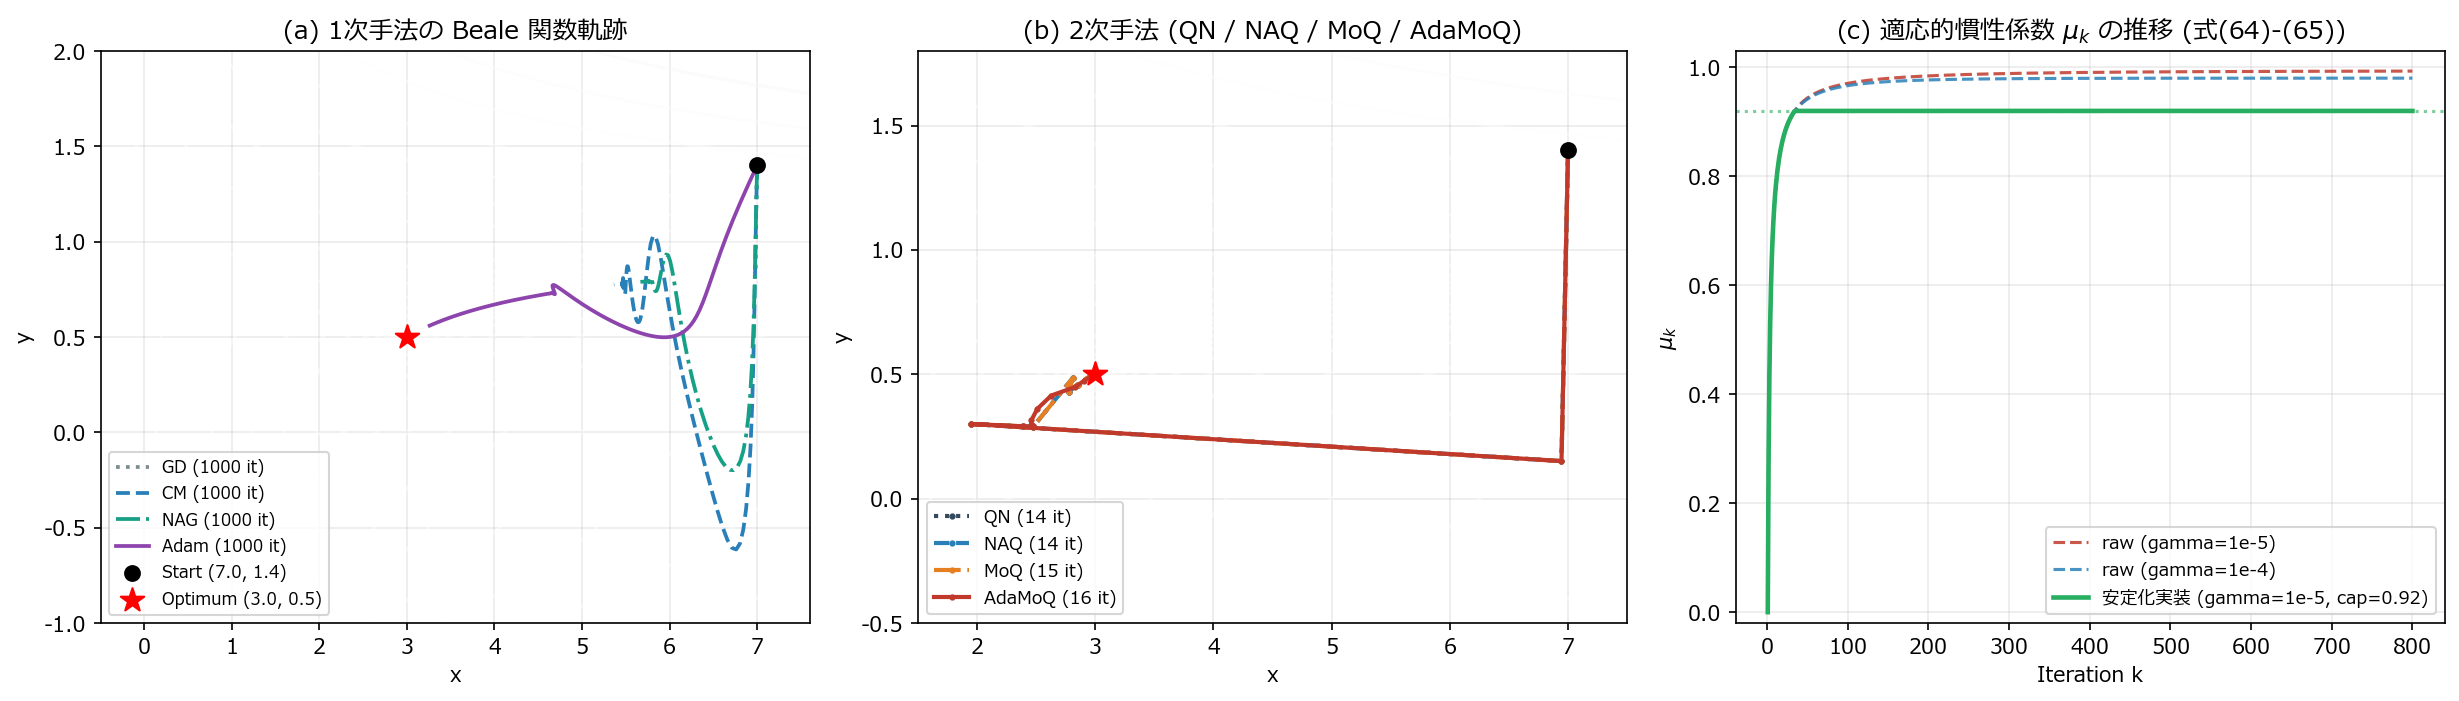

,Algorithm,Iters,"Final (x, y)","Final f(x, y)"
0,GD,1000,"(6.9802, 0.8356)",2.247e-01
1,CM,1000,"(5.3640, 0.7743)",1.561e-01
2,NAG,1000,"(5.6673, 0.7891)",1.717e-01
3,AdaGrad,1000,"(6.6863, 0.8271)",2.146e-01
4,RMSprop,1000,"(2.5232, 0.4725)",2.479e-01
5,AdaDelta,1000,"(6.3843, 0.8046)",2.521e-01
6,Adam,1000,"(3.2597, 0.5599)",8.345e-03
7,QN,14,"(3.0000, 0.5000)",1.701e-15
8,NAQ,14,"(3.0000, 0.5000)",9.299e-18
9,MoQ,15,"(3.0000, 0.5000)",1.290e-16


In [3]:
beale_res = run_beale_trajectories(x0=7.0, y0=1.4, eps=1e-6, k_max=1000)
beale_rows = [
    {
        'Algorithm': name,
        'Iters': d['iters'],
        'Final (x, y)': f"({d['final_w'][0]:.4f}, {d['final_w'][1]:.4f})",
        'Final f(x, y)': f"{d['final_f']:.3e}",
    }
    for name, d in beale_res.items()
]
display_df_beale = pd.DataFrame(beale_rows)
print(display_df_beale.to_string(index=False))

# 図1: Beale 等高線上の軌跡 (1次手法 vs 2次手法) + 適応的 mu_k の挙動
gx = np.linspace(-1.0, 8.0, 220)
gy = np.linspace(-1.2, 2.2, 180)
GX, GY = np.meshgrid(gx, gy)
Z = (1.5 - GX + GX * GY) ** 2 + (2.25 - GX + GX * GY ** 2) ** 2 + (2.625 - GX + GX * GY ** 3) ** 2
levels = np.logspace(-2, 4.5, 22)

fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.8))

# (a) 1次手法
ax = axes[0]
ax.contour(GX, GY, Z, levels=levels, cmap='Greys', alpha=0.45)
for name, col, ls in [('GD', '#7f8c8d', ':'), ('CM', '#2980b9', '--'), ('NAG', '#16a085', '-.'), ('Adam', '#8e44ad', '-')]:
    tr = beale_res[name]['traj']
    ax.plot(tr[:, 0], tr[:, 1], label=f"{name} ({beale_res[name]['iters']} it)", color=col, linestyle=ls, linewidth=1.8)
ax.scatter([7.0], [1.4], c='black', s=50, zorder=5, label='Start (7.0, 1.4)')
ax.scatter([3.0], [0.5], c='red', marker='*', s=140, zorder=6, label='Optimum (3.0, 0.5)')
ax.set_title('(a) 1次手法の Beale 関数軌跡')
ax.set_xlabel('x'); ax.set_ylabel('y')
ax.set_xlim(-0.5, 7.6); ax.set_ylim(-1.0, 2.0)
ax.legend(fontsize=8, loc='lower left')
ax.grid(alpha=0.25)

# (b) 2次手法
ax = axes[1]
ax.contour(GX, GY, Z, levels=levels, cmap='Greys', alpha=0.45)
for name, col, ls in [('QN', '#34495e', ':'), ('NAQ', '#2980b9', '--'), ('MoQ', '#e67e22', '-.'), ('AdaMoQ', '#c0392b', '-')]:
    tr = beale_res[name]['traj']
    ax.plot(tr[:, 0], tr[:, 1], marker='.', markersize=4, label=f"{name} ({beale_res[name]['iters']} it)", color=col, linestyle=ls, linewidth=2.0)
ax.scatter([7.0], [1.4], c='black', s=50, zorder=5)
ax.scatter([3.0], [0.5], c='red', marker='*', s=140, zorder=6)
ax.set_title('(b) 2次手法 (QN / NAQ / MoQ / AdaMoQ)')
ax.set_xlabel('x'); ax.set_ylabel('y')
ax.set_xlim(1.5, 7.5); ax.set_ylim(-0.5, 1.8)
ax.legend(fontsize=8.5, loc='lower left')
ax.grid(alpha=0.25)

# (c) 適応的慣性係数 mu_k (式(64)-(65)) と安全上限キャップ
ax = axes[2]
for gm, col, label_g in [(1e-5, '#c0392b', 'raw (gamma=1e-5)'), (1e-4, '#2980b9', 'raw (gamma=1e-4)')]:
    th = 1.0
    mus = []
    for _ in range(800):
        mk, th = adaptive_momentum_step_scalar(th, gamma=gm)
        mus.append(mk)
    ax.plot(np.arange(1, 801), mus, color=col, linestyle='--', alpha=0.85, label=label_g)
th = 1.0
mus_cap = []
for _ in range(800):
    mk, th = adaptive_momentum_step_scalar(th, gamma=1e-5)
    mus_cap.append(min(mk, 0.92))
ax.plot(np.arange(1, 801), mus_cap, color='#27ae60', linewidth=2.2, label='安定化実装 (gamma=1e-5, cap=0.92)')
ax.axhline(0.92, color='#27ae60', linestyle=':', alpha=0.6)
ax.set_title('(c) 適応的慣性係数 $\\mu_k$ の推移 (式(64)-(65))')
ax.set_xlabel('Iteration k'); ax.set_ylabel('$\\mu_k$')
ax.set_ylim(-0.02, 1.03)
ax.legend(fontsize=8.5, loc='lower right')
ax.grid(alpha=0.25)

plt.tight_layout()
plt.savefig('../report/img/ex001_beale_and_adaptive_mu.png', dpi=150, bbox_inches='tight')
plt.show()
display_df_beale

## 3. 実験 1A: 2次元非線形関数 $f_1(x, a)$ の近似 (`2-55-1`, $d=221$, $R=10$)

In [4]:
ds_f1 = load_or_create_f1_2d_dataset(dataset_dir='../datasets', seed=2023, device=device)
print(f"Train: {tuple(ds_f1['X_train_64'].shape)}, Test: {tuple(ds_f1['X_test_64'].shape)}")

n_in_1a, n_hid_1a = 2, 55
d_w_1a = n_in_1a * n_hid_1a + n_hid_1a + n_hid_1a * 1 + 1  # 221
R = 10
w_init_1a = generate_initial_weights(R, d_w_1a, seed=2023, device=device)

res_1a_list = []
res_1a_map = {}

# 1次手法ベースライン (max_epochs=10000)
for algo, kw in [
    ('GD', dict(mu=0.0)),
    ('CM', dict(mu=0.9)),
    ('NAG', dict(mu=0.9)),
    ('OptNAG', dict(mu=0.0)),
    ('AdaGrad', dict(lr=0.1)),
    ('RMSprop', dict(lr=0.01)),
    ('AdaDelta', dict(lr=1.0)),
    ('Adam', dict(lr=0.01)),
]:
    r = run_first_order_batched(
        algo=algo, w_init=w_init_1a,
        X_train=ds_f1['X_train_64'], XT_train=ds_f1['XT_train_64'], D_train=ds_f1['D_train_64'],
        X_test=ds_f1['X_test_64'], D_test=ds_f1['D_test_64'],
        n_in=n_in_1a, n_hid=n_hid_1a, max_epochs=10000, record_stride=250, show_pbar=False, **kw
    )
    res_1a_list.append(r)
    res_1a_map[algo] = r
    print(f"[1st] {algo:8s} | E_tr_med={r['train_median']:.3f} | Time={r['ave_time_sec']:.3f}s")

# 2次手法ファミリー (max_epochs=6000, loss_stop=5e-4)
for algo in ('QN', 'MSQN', 'NAQ', 'AdaNAQ', 'MoQ', 'AdaMoQ'):
    r = run_second_order_batched(
        algo=algo, w_init=w_init_1a,
        X_train=ds_f1['X_train_64'], XT_train=ds_f1['XT_train_64'], D_train=ds_f1['D_train_64'],
        X_test=ds_f1['X_test_64'], D_test=ds_f1['D_test_64'],
        n_in=n_in_1a, n_hid=n_hid_1a, mu=0.85, max_epochs=6000, loss_stop=5e-4, record_stride=100, show_pbar=False
    )
    res_1a_list.append(r)
    res_1a_map[algo] = r
    print(f"[2nd] {algo:8s} | E_tr_med={r['train_median']:.4f} | E_te_med={r['test_median']:.4f} | Time={r['ave_time_sec']:.3f}s | Conv={r['conv_rate']:.1f}%")

df_1a = format_moq_dataframe(res_1a_list, precision=3)
df_1a.to_csv('../datasets/ex001_f1_2d_results.csv', index=False, encoding='utf-8')
df_1a

Train: (3320, 2), Test: (6600, 2)
[1st] GD       | E_tr_med=41.013 | Time=4.066s
[1st] CM       | E_tr_med=40.898 | Time=3.821s
[1st] NAG      | E_tr_med=41.018 | Time=2.521s
[1st] OptNAG   | E_tr_med=41.013 | Time=5.082s
[1st] AdaGrad  | E_tr_med=38.421 | Time=0.600s
[1st] RMSprop  | E_tr_med=33.421 | Time=0.605s
[1st] AdaDelta | E_tr_med=44.153 | Time=0.626s
[1st] Adam     | E_tr_med=28.957 | Time=0.619s
[2nd] QN       | E_tr_med=4.7762 | E_te_med=4.9406 | Time=1.284s | Conv=0.0%
[2nd] MSQN     | E_tr_med=4.4408 | E_te_med=3.9778 | Time=1.662s | Conv=0.0%
[2nd] NAQ      | E_tr_med=2.3399 | E_te_med=2.3081 | Time=1.648s | Conv=0.0%
[2nd] AdaNAQ   | E_tr_med=3.9154 | E_te_med=3.5539 | Time=1.965s | Conv=0.0%
[2nd] MoQ      | E_tr_med=4.2180 | E_te_med=4.0637 | Time=1.750s | Conv=0.0%
[2nd] AdaMoQ   | E_tr_med=3.8397 | E_te_med=3.9445 | Time=1.419s | Conv=0.0%


,Algorithm,mu,E_train (x10^3) Med/Ave/Best/Worst,Est. Time(s),Per Iter(ms),Ave. Iters,E_test (x10^3) Med/Ave/Best/Worst,Conv(%)
0,GD,-,41.013 / 41.013 / 41.003 / 41.019,4.066,0.4066,10000,40.530 / 40.532 / 40.526 / 40.540,0.0
1,CM,0.90,40.898 / 40.859 / 40.609 / 40.978,3.821,0.3821,10000,40.383 / 40.333 / 40.021 / 40.495,0.0
2,NAG,0.90,41.018 / 41.055 / 40.976 / 41.145,2.521,0.2793,9025,40.539 / 40.545 / 40.487 / 40.581,10.0
3,OptNAG,-,41.013 / 41.013 / 41.003 / 41.019,5.082,0.5082,10000,40.530 / 40.532 / 40.526 / 40.540,0.0
4,AdaGrad,-,38.421 / 38.401 / 36.378 / 39.788,0.600,0.0600,10000,37.783 / 37.759 / 35.810 / 39.119,0.0
5,RMSprop,-,33.421 / 33.402 / 33.018 / 33.891,0.605,0.0605,10000,32.736 / 32.777 / 32.443 / 33.296,0.0
6,AdaDelta,-,44.153 / 44.167 / 44.067 / 44.319,0.626,0.0626,10000,43.718 / 43.735 / 43.555 / 43.950,0.0
7,Adam,-,28.957 / 29.027 / 28.269 / 30.254,0.619,0.0619,10000,28.409 / 28.431 / 27.703 / 29.694,0.0
8,QN,-,4.776 / 4.712 / 1.143 / 7.886,1.284,0.2141,6000,4.941 / 4.689 / 1.217 / 7.841,0.0
9,MSQN,-,4.441 / 5.134 / 1.762 / 8.767,1.662,0.2770,6000,3.978 / 5.086 / 2.159 / 9.128,0.0


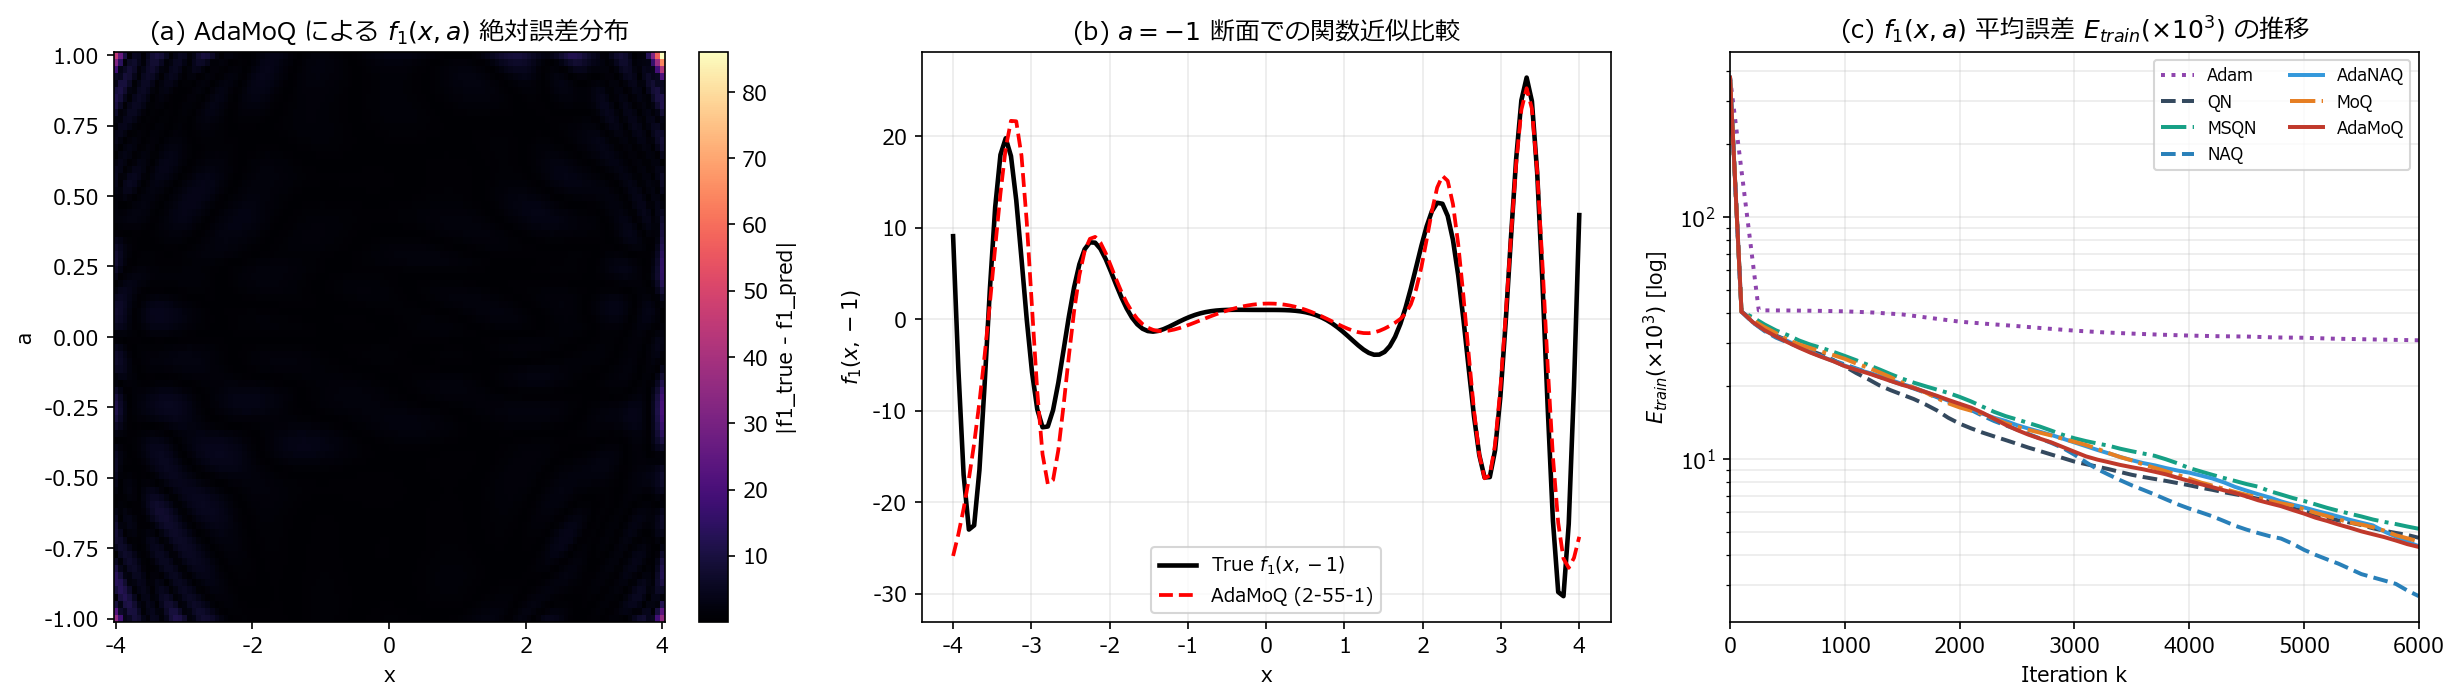

In [5]:
# 図2: f1(x, a) の近似曲面 (AdaMoQ) と a=-1 断面，および 1次・2次手法の収束比較
from model import BatchedMLP
stats = ds_f1['norm_stats']
x_min, x_max = stats['x_min'], stats['x_max']
y_min, y_max = stats['y_min'], stats['y_max']

xg = np.linspace(-4.0, 4.0, 120)
ag = np.linspace(-1.0, 1.0, 80)
XG, AG = np.meshgrid(xg, ag, indexing='ij')
Z_true = target_function_f1_2d(XG, AG)
X_grid_raw = np.stack([XG.ravel(), AG.ravel()], axis=1)
X_grid_n = torch.tensor(2.0 * (X_grid_raw - x_min) / (x_max - x_min) - 1.0, device=device, dtype=torch.float64)
bmlp = BatchedMLP(n_in_1a, n_hid_1a, 1)
with torch.no_grad():
    y_pred_n = bmlp.predict(res_1a_map['AdaMoQ']['best_weights'].unsqueeze(0), X_grid_n).squeeze(0).squeeze(-1).cpu().numpy()
Z_pred = (y_pred_n + 1.0) * 0.5 * (y_max - y_min) + y_min
Z_pred = Z_pred.reshape(XG.shape)

fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.8))

# (a) 2D 絶対誤差ヒートマップ
ax = axes[0]
pcm = ax.pcolormesh(XG, AG, np.abs(Z_true - Z_pred), shading='auto', cmap='magma')
fig.colorbar(pcm, ax=ax, label='|f1_true - f1_pred|')
ax.set_title('(a) AdaMoQ による $f_1(x, a)$ 絶対誤差分布')
ax.set_xlabel('x'); ax.set_ylabel('a')

# (b) a = -1 断面における真値 vs 予測
ax = axes[1]
ax.plot(xg, Z_true[:, 0], 'k-', linewidth=2.2, label='True $f_1(x, -1)$')
ax.plot(xg, Z_pred[:, 0], 'r--', linewidth=1.8, label='AdaMoQ (2-55-1)')
ax.set_title('(b) $a=-1$ 断面での関数近似比較')
ax.set_xlabel('x'); ax.set_ylabel('$f_1(x, -1)$')
ax.legend(fontsize=9)
ax.grid(alpha=0.25)

# (c) 収束曲線 (平均 E_train x 10^3 vs Iteration)
ax = axes[2]
for name, col, ls in [
    ('Adam', '#8e44ad', ':'), ('QN', '#34495e', '--'), ('MSQN', '#16a085', '-.'),
    ('NAQ', '#2980b9', '--'), ('AdaNAQ', '#3498db', '-'), ('MoQ', '#e67e22', '-.'), ('AdaMoQ', '#c0392b', '-')
]:
    r = res_1a_map[name]
    ax.plot(r['rec_epochs'], np.clip(r['rec_means'] * 1e3, 1e-4, None), label=name, color=col, linestyle=ls, linewidth=1.9)
ax.set_yscale('log')
ax.set_xlim(0, 6000)
ax.set_title('(c) $f_1(x, a)$ 平均誤差 $E_{train} (\\times 10^3)$ の推移')
ax.set_xlabel('Iteration k'); ax.set_ylabel('$E_{train} (\\times 10^3)$ [log]')
ax.legend(fontsize=8, ncol=2)
ax.grid(alpha=0.25, which='both')

plt.tight_layout()
plt.savefig('../report/img/ex001_f1_approximation.png', dpi=150, bbox_inches='tight')
plt.show()

## 4. 実験 1B: 5次元 Levy 関数 (式(102)) の関数近似 (`5-50-1`, $d=351$, $R=10$)

In [6]:
ds_levy = load_or_create_levy_5d_dataset(dataset_dir='../datasets', seed=2023, device=device)
print(f"5D Levy Train: {tuple(ds_levy['X_train_64'].shape)}, Test: {tuple(ds_levy['X_test_64'].shape)}")

n_in_1b, n_hid_1b = 5, 50
d_w_1b = n_in_1b * n_hid_1b + n_hid_1b + n_hid_1b * 1 + 1  # 351
w_init_1b = generate_initial_weights(R, d_w_1b, seed=2024, device=device)

res_1b_list = []
res_1b_map = {}
for algo in ('QN', 'MSQN', 'NAQ', 'AdaNAQ', 'MoQ', 'AdaMoQ'):
    r = run_second_order_batched(
        algo=algo, w_init=w_init_1b,
        X_train=ds_levy['X_train_64'], XT_train=ds_levy['XT_train_64'], D_train=ds_levy['D_train_64'],
        X_test=ds_levy['X_test_64'], D_test=ds_levy['D_test_64'],
        n_in=n_in_1b, n_hid=n_hid_1b, mu=0.85, max_epochs=3000, loss_stop=1e-3, record_stride=100, show_pbar=False
    )
    res_1b_list.append(r)
    res_1b_map[algo] = r
    print(f"{algo:8s} | E_tr_med={r['train_median']:.4f} | E_te_med={r['test_median']:.4f} | PerIter={r['per_iter_ms']:.3f}ms | Conv={r['conv_rate']:.1f}%")

df_1b = format_moq_dataframe(res_1b_list, precision=3)
df_1b.to_csv('../datasets/ex001_levy_5d_results.csv', index=False, encoding='utf-8')
df_1b

5D Levy Train: (5000, 5), Test: (2500, 5)
QN       | E_tr_med=13.8234 | E_te_med=18.9272 | PerIter=0.176ms | Conv=0.0%
MSQN     | E_tr_med=13.8070 | E_te_med=18.9862 | PerIter=0.193ms | Conv=0.0%
NAQ      | E_tr_med=13.6715 | E_te_med=18.9008 | PerIter=0.300ms | Conv=0.0%
AdaNAQ   | E_tr_med=13.7003 | E_te_med=18.9776 | PerIter=0.345ms | Conv=0.0%
MoQ      | E_tr_med=13.7142 | E_te_med=19.0290 | PerIter=0.292ms | Conv=0.0%
AdaMoQ   | E_tr_med=13.7046 | E_te_med=19.0082 | PerIter=0.303ms | Conv=0.0%


,Algorithm,mu,E_train (x10^3) Med/Ave/Best/Worst,Est. Time(s),Per Iter(ms),Ave. Iters,E_test (x10^3) Med/Ave/Best/Worst,Conv(%)
0,QN,-,13.823 / 13.832 / 13.620 / 13.977,0.528,0.1760,3000,18.927 / 18.839 / 18.317 / 19.178,0.0
1,MSQN,-,13.807 / 13.792 / 13.585 / 13.958,0.579,0.1931,3000,18.986 / 19.069 / 18.662 / 20.134,0.0
2,NAQ,0.85,13.672 / 13.630 / 13.383 / 13.941,0.901,0.3002,3000,18.901 / 19.007 / 18.579 / 19.975,0.0
3,AdaNAQ,-,13.700 / 13.696 / 13.493 / 13.850,1.034,0.3447,3000,18.978 / 18.972 / 18.651 / 19.275,0.0
4,MoQ,0.85,13.714 / 13.684 / 13.435 / 13.808,0.876,0.2920,3000,19.029 / 19.256 / 18.735 / 20.757,0.0
5,AdaMoQ,-,13.705 / 13.719 / 13.575 / 14.017,0.908,0.3025,3000,19.008 / 19.056 / 18.615 / 19.675,0.0


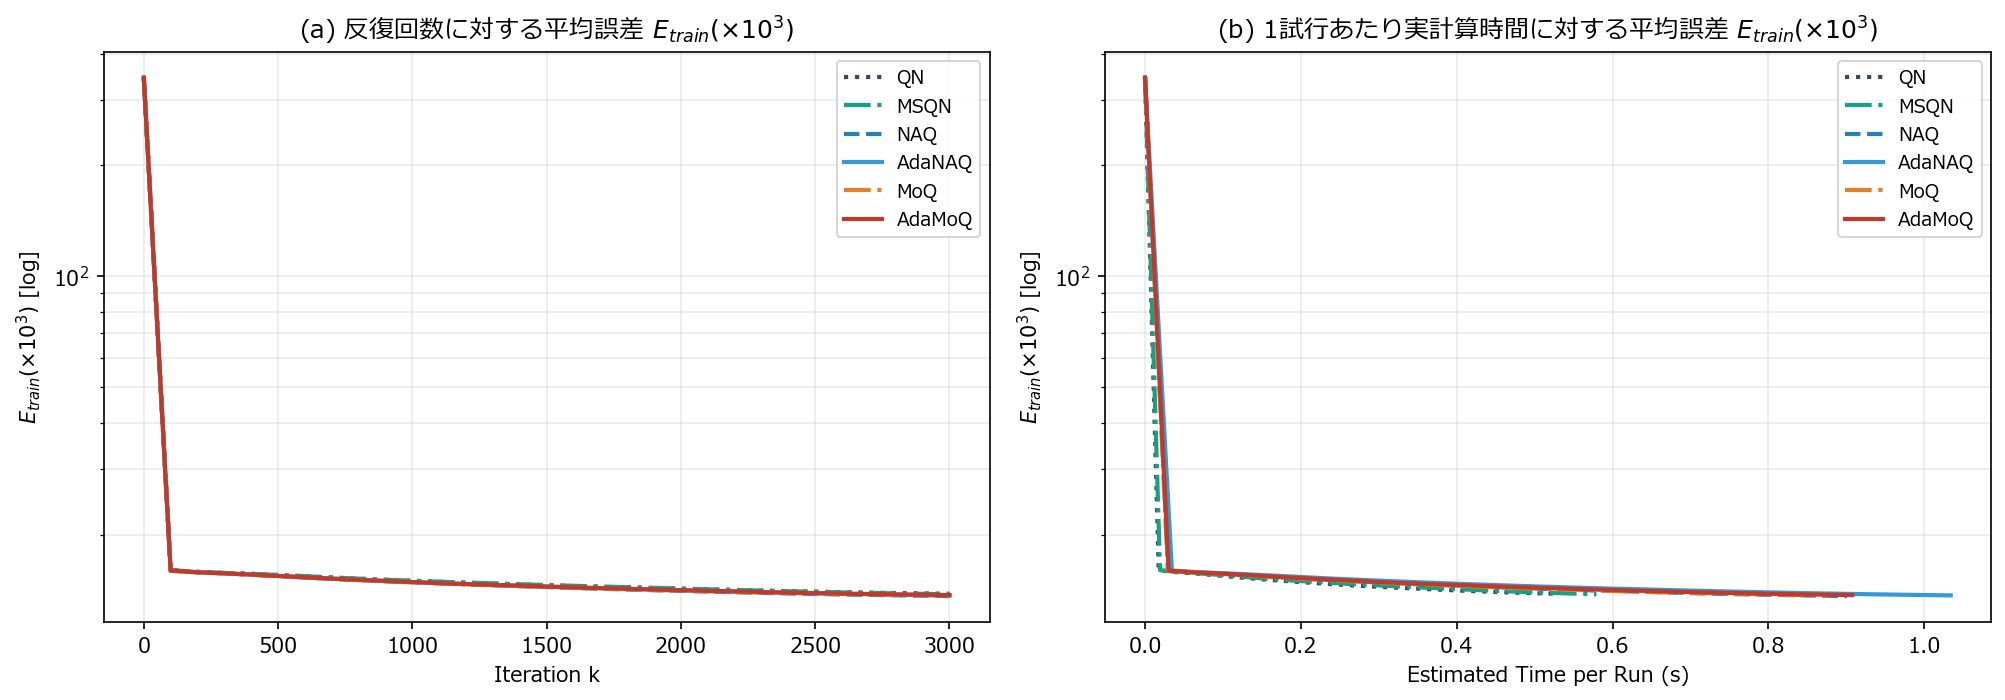

In [7]:
# 図3: 5次元 Levy 関数の収束曲線 (反復回数軸 vs 実計算時間軸)
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))
styles = [
    ('QN', '#34495e', ':'), ('MSQN', '#16a085', '-.'), ('NAQ', '#2980b9', '--'),
    ('AdaNAQ', '#3498db', '-'), ('MoQ', '#e67e22', '-.'), ('AdaMoQ', '#c0392b', '-')
]

for name, col, ls in styles:
    r = res_1b_map[name]
    axes[0].plot(r['rec_epochs'], np.clip(r['rec_means'] * 1e3, 1e-4, None), label=name, color=col, linestyle=ls, linewidth=2.0)
    # 10試行同時並列の実測タイムを 1試行平均計算時間へ正規化して比較表示
    est_t = r['rec_epochs'] * (r['per_iter_ms'] / 1000.0)
    axes[1].plot(est_t, np.clip(r['rec_means'] * 1e3, 1e-4, None), label=name, color=col, linestyle=ls, linewidth=2.0)

axes[0].set_yscale('log')
axes[0].set_title('(a) 反復回数に対する平均誤差 $E_{train} (\\times 10^3)$')
axes[0].set_xlabel('Iteration k'); axes[0].set_ylabel('$E_{train} (\\times 10^3)$ [log]')
axes[0].legend(fontsize=9); axes[0].grid(alpha=0.25, which='both')

axes[1].set_yscale('log')
axes[1].set_title('(b) 1試行あたり実計算時間に対する平均誤差 $E_{train} (\\times 10^3)$')
axes[1].set_xlabel('Estimated Time per Run (s)'); axes[1].set_ylabel('$E_{train} (\\times 10^3)$ [log]')
axes[1].legend(fontsize=9); axes[1].grid(alpha=0.25, which='both')

plt.tight_layout()
plt.savefig('../report/img/ex001_levy_convergence.png', dpi=150, bbox_inches='tight')
plt.show()